<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/05_imputation_tuning_ansel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: impute missing values instead of dropping rows, compare the two, and re-tune the tree and k-NN

Notebook 04 dropped every game with a missing input, which removed 3,649 of the 21,631 games (17%). This notebook keeps those games and fills in the missing inputs instead, then answers three questions:

1. **How much is missing, and does dropping it bias the rows we keep?**
2. **Which way of filling in works best?** Five imputers compared by 5-fold cross-validation on the training rows.
3. **Does imputing beat dropping?** The regression tree and k-NN are re-tuned by cross-validation under both approaches, with train-versus-validation sweeps, and scored once on the same test games.

Ground rules followed: same loading cell as notebooks 02 to 04; `train_test_split(test_size=0.3, random_state=1)`; RMSE with MAE and R² next to scikit-learn's `DummyRegressor`; no post-release columns as inputs; every imputer, scaler and encoder fitted on training rows only, inside a `Pipeline` during cross-validation; the test rows scored once, at the end.

In [1]:
# --- Ansel Weng: task 1, imputing missing inputs instead of dropping rows, comparing the two, re-tuning the tree and k-NN ---
# [AI-assisted] Claude Code, 2026-11-10. Every code and markdown cell in this notebook was generated with Claude Code from notebook 04 and the course labs; reviewed and edited by Ansel Weng.
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401, switches on IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Load the data

In [2]:
# [AI-assisted] Claude Code, 2026-11-10. Same loading cell as notebooks 02 to 04; reviewed and edited by Ansel Weng.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code, 2026-11-10. Figure folder helper, as in notebook 04; reviewed and edited by Ansel Weng.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

## 2. How much is missing, and does dropping it bias what is left?

The inputs are notebook 04's: year of publication, player-count range, play-time range, minimum age, the number of mechanics and categories, and 0/1 columns for the most common mechanics and categories. The target, `average`, is never missing.

In [4]:
# [AI-assisted] Claude Code, 2026-11-10. Missing share per input column, and the number of games with at least one missing input; reviewed and edited by Ansel Weng.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
needed = numeric_cols + ["boardgamemechanic", "boardgamecategory"]
missing = pd.DataFrame({"games missing": games[needed].isna().sum(), "share missing (%)": (100 * games[needed].isna().mean()).round(2)})
games["complete"] = games[needed].notna().all(axis=1)
print("games with every input known:", games["complete"].sum(), "| with at least one missing:", (~games["complete"]).sum(),
      f"({100 * (~games['complete']).mean():.1f}% of {len(games):,})")
missing.sort_values("games missing", ascending=False)

games with every input known: 17982 | with at least one missing: 3649 (16.9% of 21,631)


,games missing,share missing (%)
n_mechanics,1590,7.35
boardgamemechanic,1590,7.35
minage,1301,6.01
maxplaytime,774,3.58
minplaytime,642,2.97
n_categories,283,1.31
boardgamecategory,283,1.31
yearpublished,195,0.90
maxplayers,164,0.76
minplayers,44,0.20


In [5]:
# [AI-assisted] Claude Code, 2026-11-10. Compare games with and without a missing input on the target and on post-release popularity; reviewed and edited by Ansel Weng.
# users_rated is used here only to describe the two groups, never as an input.
compare = games.groupby("complete").agg(games=("average", "size"), mean_rating=("average", "mean"), median_rating=("average", "median"),
                                        sd_rating=("average", "std"), median_users_rated=("users_rated", "median"), median_year=("yearpublished", "median"))
compare.index = compare.index.map({True: "every input known", False: "at least one input missing"})
compare.round(2)

,games,mean_rating,median_rating,sd_rating,median_users_rated,median_year
complete,,,,,,
at least one input missing,3649,6.17,6.17,1.04,64.0,2009.0
every input known,17982,6.47,6.50,0.90,148.0,2012.0


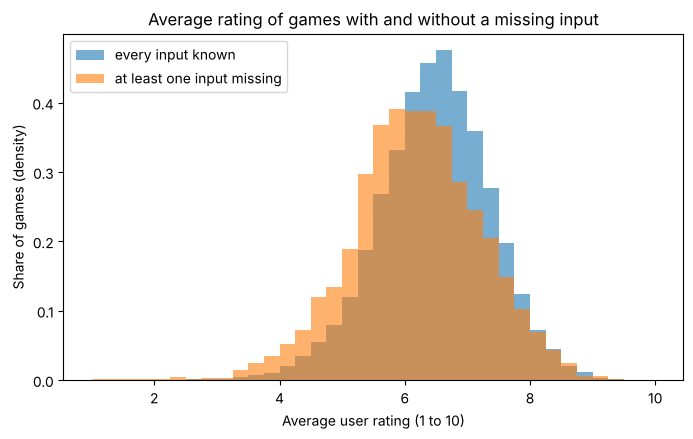

In [6]:
# [AI-assisted] Claude Code, 2026-11-10. Rating distribution of the two groups; reviewed and edited by Ansel Weng.
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(1, 10.01, 0.25)
ax.hist(games.loc[games["complete"], "average"], bins=bins, density=True, alpha=0.6, label="every input known")
ax.hist(games.loc[~games["complete"], "average"], bins=bins, density=True, alpha=0.6, label="at least one input missing")
ax.set_title("Average rating of games with and without a missing input")
ax.set_xlabel("Average user rating (1 to 10)")
ax.set_ylabel("Share of games (density)")
ax.legend()
save("05_rating_by_missingness.png")
plt.show()

**Takeaway:** 3,649 games (16.9%) have at least one missing input, mostly the mechanic list (7.4%) and minimum age (6.0%). They are **not a random 17%**: their mean rating is 6.17 against 6.47 for complete games, their ratings are more spread out (standard deviation 1.04 against 0.90), and they have fewer raters (median 64 against 148). Dropping them leaves a catalogue tilted towards better-rated, better-known games, and a model that cannot say anything about the kind of game most likely to arrive with incomplete information. That is the case for imputing rather than dropping.

## 3. One split of every game, then the inputs

All 21,631 games are split once, 70/30 with `random_state=1`. The **drop** approach uses only the games in each half with every input known; the **impute** approach uses every game. Because both come from the same split, the complete test games are identical for the two approaches, which is what makes the final comparison fair.

As in notebook 04, the list of the most common mechanics and categories is taken from the training rows only. A game whose mechanic or category list is missing gets 0 in those 0/1 columns, and its missing `n_mechanics` or `n_categories` is what the imputer fills in.

In [7]:
# [AI-assisted] Claude Code, 2026-11-10. 70/30 split of all games, and the complete-case subset on each side; reviewed and edited by Ansel Weng.
train_df, test_df = train_test_split(games, test_size=0.3, random_state=1)
y_train, y_test = train_df["average"], test_df["average"]
train_complete, test_complete = train_df["complete"].values, test_df["complete"].values
print("training games:", len(train_df), "| of which complete:", train_complete.sum())
print("test games:    ", len(test_df), "| of which complete:", test_complete.sum(), "| with a missing input:", (~test_complete).sum())

training games: 15141 | of which complete: 12611
test games:     6490 | of which complete: 5371 | with a missing input: 1119


In [8]:
# [AI-assisted] Claude Code, 2026-11-10. Same input builder as notebook 04; log10 of NaN stays NaN, so missing values pass through to the imputer; reviewed and edited by Ansel Weng.
N_MECH, N_CAT = 20, 15
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_MECH).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_CAT).index

def build_inputs(frame, numeric, mechanics, categories):
    X = frame[numeric].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        if col in X.columns:
            X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df, numeric_cols, top_mech, top_cat)
X_test = build_inputs(test_df, numeric_cols, top_mech, top_cat)
print("inputs:", X_train.shape[1], "columns | missing cells in the training inputs:", int(X_train.isna().sum().sum()))

inputs: 43 columns | missing cells in the training inputs: 3497


In [9]:
# [AI-assisted] Claude Code, 2026-11-10. Scoring helpers, cross-validation folds, and the DummyRegressor baseline; reviewed and edited by Ansel Weng.
folds = KFold(n_splits=5, shuffle=True, random_state=0)
RMSE = "neg_root_mean_squared_error"

def test_scores(y_true, pred):
    return {"test RMSE": np.sqrt(mean_squared_error(y_true, pred)), "test MAE": mean_absolute_error(y_true, pred), "test R2": r2_score(y_true, pred)}

def cv_rmse(model, X, y):
    # Mean 5-fold cross-validated RMSE on the given training rows, plus the mean training-fold RMSE.
    cv = cross_validate(model, X, y, cv=folds, scoring=RMSE, return_train_score=True)
    return -cv["test_score"].mean(), -cv["train_score"].mean()

## 4. Which way of filling in works best?

Five imputers, each placed as the first step of a `Pipeline`, so that during cross-validation it is fitted on the four training folds only and then applied to the fifth:

| Imputer | What it fills in |
| --- | --- |
| mean | the column's training mean |
| median | the column's training median (robust to the long tails in play time and player count) |
| median + indicator | the median, plus a 0/1 column per input saying "this was missing", so the model can learn whether missingness itself carries information |
| k-NN imputer | the average of the 5 most similar training games on the inputs that are known (inputs standardized first) |
| iterative | each column predicted from the others by a regression, repeated until stable (`IterativeImputer`) |

Each imputer is scored with three models held at notebook 04's tuned settings (linear regression, tree with depth 10 and 50 games per leaf, k-NN with k = 30 and distance weights), so that only the imputer changes.

In [10]:
# [AI-assisted] Claude Code, 2026-11-10. Imputer factory and model pipelines; reviewed and edited by Ansel Weng.
def make_imputer(name):
    if name == "mean":
        return SimpleImputer(strategy="mean")
    if name == "median":
        return SimpleImputer(strategy="median")
    if name == "median + indicator":
        return SimpleImputer(strategy="median", add_indicator=True)
    if name == "k-NN imputer":
        return make_pipeline(StandardScaler(), KNNImputer(n_neighbors=5))
    if name == "iterative":
        return IterativeImputer(max_iter=10, random_state=0)
    raise ValueError(name)

def tree_pipe(imputer, **kw):
    return Pipeline([("impute", make_imputer(imputer)), ("model", DecisionTreeRegressor(random_state=0, **kw))])

def knn_pipe(imputer, **kw):
    return Pipeline([("impute", make_imputer(imputer)), ("scale", StandardScaler()), ("model", KNeighborsRegressor(**kw))])

def lin_pipe(imputer):
    return Pipeline([("impute", make_imputer(imputer)), ("model", LinearRegression())])

IMPUTERS = ["mean", "median", "median + indicator", "k-NN imputer", "iterative"]

In [11]:
# [AI-assisted] Claude Code, 2026-11-10. 5-fold cross-validated RMSE on all training games for every imputer and model; reviewed and edited by Ansel Weng.
rows = []
for name in IMPUTERS:
    start = time.time()
    rows.append({
        "imputer": name,
        "linear": cv_rmse(lin_pipe(name), X_train, y_train)[0],
        "tree (depth 10, leaf 50)": cv_rmse(tree_pipe(name, max_depth=10, min_samples_leaf=50), X_train, y_train)[0],
        "k-NN (k 30, distance)": cv_rmse(knn_pipe(name, n_neighbors=30, weights="distance"), X_train, y_train)[0],
        "seconds": time.time() - start,
    })
imputer_table = pd.DataFrame(rows).set_index("imputer")
imputer_table.round(4)

,linear,"tree (depth 10, leaf 50)","k-NN (k 30, distance)",seconds
imputer,,,,
mean,0.7649,0.7100,0.7593,2.0799
median,0.7649,0.7130,0.7594,2.7009
median + indicator,0.7539,0.7117,0.7598,2.7296
k-NN imputer,0.7580,0.7107,0.7579,69.0948
iterative,0.7575,0.7113,0.7581,231.0220


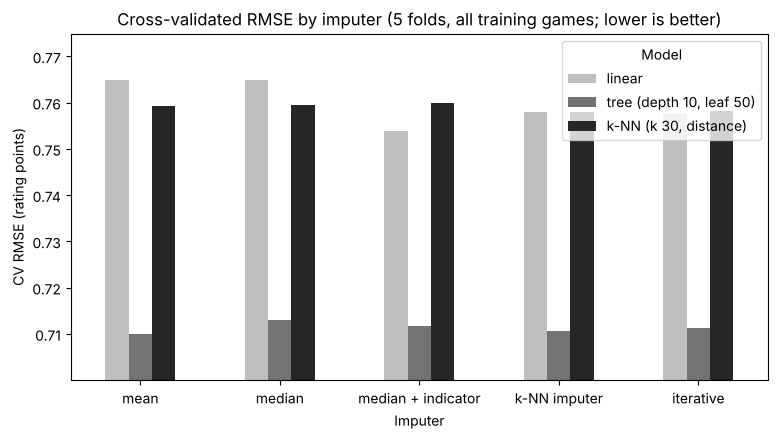

In [12]:
# [AI-assisted] Claude Code, 2026-11-10. Chart of the imputer comparison; reviewed and edited by Ansel Weng.
ax = imputer_table.drop(columns="seconds").plot(kind="bar", figsize=(9, 4.5), rot=0, color=["0.75", "0.45", "0.15"])
lo = imputer_table.drop(columns="seconds").values.min()
hi = imputer_table.drop(columns="seconds").values.max()
ax.set_ylim(lo - 0.01, hi + 0.01)
ax.set_title("Cross-validated RMSE by imputer (5 folds, all training games; lower is better)")
ax.set_xlabel("Imputer")
ax.set_ylabel("CV RMSE (rating points)")
ax.legend(title="Model", loc="upper right")
save("05_imputer_comparison.png")
plt.show()

**Takeaway:** the choice of imputer barely matters for the tree and k-NN: their cross-validated RMSE varies by at most 0.003 across all five. It matters more for linear regression, where **median + indicator** is clearly best (0.754, against 0.758 to 0.765 for the others): the "was missing" columns let the model learn that games with missing information rate lower, which no single filled-in value can express.

The k-NN and iterative imputers are within 0.002 of median + indicator for the tree and k-NN, but take roughly 25 and 90 times as long, and are worse for linear regression. **Chosen: median + indicator.** It is the best or within 0.002 of the best for every model, it is fast, and it is simple to explain: fill the gap with the typical training value and flag that it was filled.

In [13]:
# [AI-assisted] Claude Code, 2026-11-10. The imputer chosen for the rest of the notebook; reviewed and edited by Ansel Weng.
IMPUTER = "median + indicator"
print("imputer used from here on:", IMPUTER)

imputer used from here on: median + indicator


## 5. Re-tune the regression tree on the imputed rows

### 5a. Sweeps: training versus validation RMSE

Notebook 04's sweeps scored the test rows at every setting. Here the sweeps use `validation_curve`, which reports the training-fold and validation-fold RMSE from 5-fold cross-validation on the training rows, so the test rows stay untouched until the end. A gap that widens between the two curves is the overfitting signal.

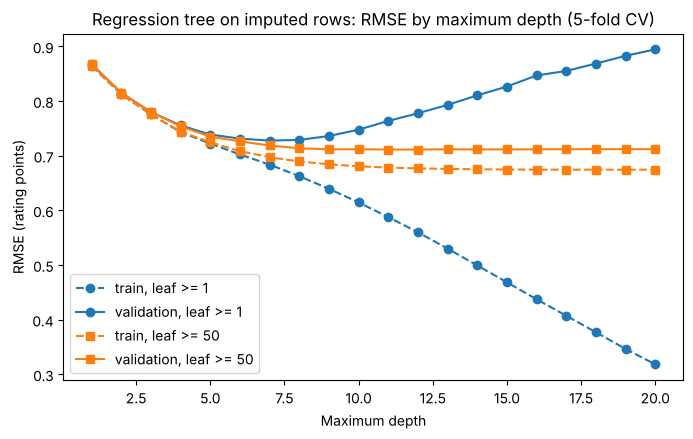

max_depth                      1      2      3      4      5      6      7   \
leaf >= 1  train RMSE       0.865  0.812  0.776  0.743  0.722  0.702  0.684   
           validation RMSE  0.867  0.815  0.780  0.755  0.739  0.731  0.728   
leaf >= 50 train RMSE       0.865  0.812  0.776  0.744  0.724  0.708  0.697   
           validation RMSE  0.867  0.815  0.780  0.754  0.735  0.726  0.719   

max_depth                      8      9      10     11     12     13     14  \
leaf >= 1  train RMSE       0.662  0.639  0.614  0.588  0.560  0.530  0.499   
           validation RMSE  0.729  0.736  0.748  0.764  0.778  0.793  0.810   
leaf >= 50 train RMSE       0.689  0.684  0.681  0.678  0.677  0.676  0.675   
           validation RMSE  0.714  0.712  0.712  0.711  0.711  0.712  0.712   

max_depth                      15     16     17     18     19     20  
leaf >= 1  train RMSE       0.468  0.437  0.407  0.377  0.346  0.318  
           validation RMSE  0.827  0.847  0.855  0.869  0.883  0.895  
leaf >= 50 train RMSE       0.675  0.675  0.674  0.674  0.674  0.674  
           validation RMSE  0.711  0.712  0.712  0.712  0.712  0.712

In [14]:
# [AI-assisted] Claude Code, 2026-11-10. Validation-curve helper and the tree depth sweep at two leaf sizes; reviewed and edited by Ansel Weng.
def sweep(model, param, values, X, y):
    train, valid = validation_curve(model, X, y, param_name=param, param_range=values, cv=folds, scoring=RMSE)
    return pd.DataFrame({"train RMSE": -train.mean(axis=1), "validation RMSE": -valid.mean(axis=1)}, index=pd.Index(values, name=param.split("__")[-1]))

depths = list(range(1, 21))
depth_sweep_1 = sweep(tree_pipe(IMPUTER, min_samples_leaf=1), "model__max_depth", depths, X_train, y_train)
depth_sweep_50 = sweep(tree_pipe(IMPUTER, min_samples_leaf=50), "model__max_depth", depths, X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, depth_sweep_1["train RMSE"], "o--", color="tab:blue", label="train, leaf >= 1")
ax.plot(depths, depth_sweep_1["validation RMSE"], "o-", color="tab:blue", label="validation, leaf >= 1")
ax.plot(depths, depth_sweep_50["train RMSE"], "s--", color="tab:orange", label="train, leaf >= 50")
ax.plot(depths, depth_sweep_50["validation RMSE"], "s-", color="tab:orange", label="validation, leaf >= 50")
ax.set_title("Regression tree on imputed rows: RMSE by maximum depth (5-fold CV)")
ax.set_xlabel("Maximum depth")
ax.set_ylabel("RMSE (rating points)")
ax.legend()
save("05_tree_depth_sweep.png")
plt.show()
pd.concat({"leaf >= 1": depth_sweep_1, "leaf >= 50": depth_sweep_50}, axis=1).round(3).T

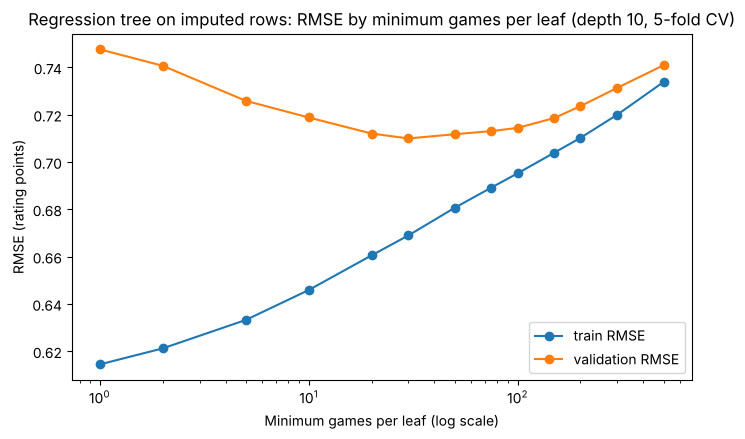

min_samples_leaf,1,2,5,10,20,30,50,75,100,150,200,300,500
train RMSE,0.614,0.621,0.633,0.646,0.661,0.669,0.681,0.689,0.695,0.704,0.710,0.720,0.734
validation RMSE,0.748,0.741,0.726,0.719,0.712,0.710,0.712,0.713,0.714,0.719,0.724,0.731,0.741


In [15]:
# [AI-assisted] Claude Code, 2026-11-10. Tree leaf-size sweep at depth 10; reviewed and edited by Ansel Weng.
leaves = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500]
leaf_sweep = sweep(tree_pipe(IMPUTER, max_depth=10), "model__min_samples_leaf", leaves, X_train, y_train)
ax = leaf_sweep.plot(marker="o", figsize=(8, 4.5), logx=True)
ax.set_title("Regression tree on imputed rows: RMSE by minimum games per leaf (depth 10, 5-fold CV)")
ax.set_xlabel("Minimum games per leaf (log scale)")
ax.set_ylabel("RMSE (rating points)")
save("05_tree_leaf_sweep.png")
plt.show()
leaf_sweep.round(3).T

**Takeaway:** with no limit on leaf size (blue), validation RMSE is lowest at depth 7 (0.728) and then climbs to 0.895 at depth 20 while training RMSE falls to 0.318: the classic overfitting gap. Requiring at least 50 games per leaf (orange) removes it: validation RMSE flattens at about 0.711 from depth 9 onward and never rises, because the leaf limit stops the tree from carving out tiny groups. At depth 10, leaf sizes below 10 overfit (0.748 at 1), sizes above 100 underfit (0.741 at 500), and 30 is lowest (0.710).

### 5b. Grid search over two hyperparameters

Maximum depth and minimum games per leaf, tuned together by 5-fold cross-validation on all training games, imputer inside the pipeline.

In [16]:
# [AI-assisted] Claude Code, 2026-11-10. GridSearchCV for the tree on imputed rows; reviewed and edited by Ansel Weng.
tree_grid_params = {"model__max_depth": [4, 6, 8, 10, 12, 15, None], "model__min_samples_leaf": [10, 20, 30, 50, 75, 100, 200]}
tree_grid = GridSearchCV(tree_pipe(IMPUTER), tree_grid_params, cv=folds, scoring=RMSE, n_jobs=-1)
tree_grid.fit(X_train, y_train)
print("best settings:", tree_grid.best_params_, "| CV RMSE:", round(-tree_grid.best_score_, 4))
table = pd.DataFrame(tree_grid.cv_results_)
table["param_model__max_depth"] = table["param_model__max_depth"].astype(object).fillna("None").astype(str)
depth_order = [str(d) for d in tree_grid_params["model__max_depth"]]
(-table.pivot(index="param_model__max_depth", columns="param_model__min_samples_leaf", values="mean_test_score")).reindex(depth_order).round(3)

best settings: {'model__max_depth': 10, 'model__min_samples_leaf': 30} | CV RMSE: 0.71


param_model__min_samples_leaf,10,20,30,50,75,100,200
param_model__max_depth,,,,,,,
4,0.754,0.754,0.754,0.754,0.754,0.753,0.753
6,0.726,0.726,0.725,0.726,0.725,0.726,0.732
8,0.716,0.713,0.712,0.714,0.716,0.717,0.725
10,0.719,0.712,0.710,0.712,0.713,0.714,0.724
12,0.727,0.715,0.711,0.711,0.712,0.714,0.724
15,0.735,0.717,0.712,0.711,0.712,0.714,0.724
None,0.744,0.720,0.713,0.712,0.712,0.714,0.724


## 6. Re-tune k-NN on the imputed rows

### 6a. Sweep of k, equal and distance weights

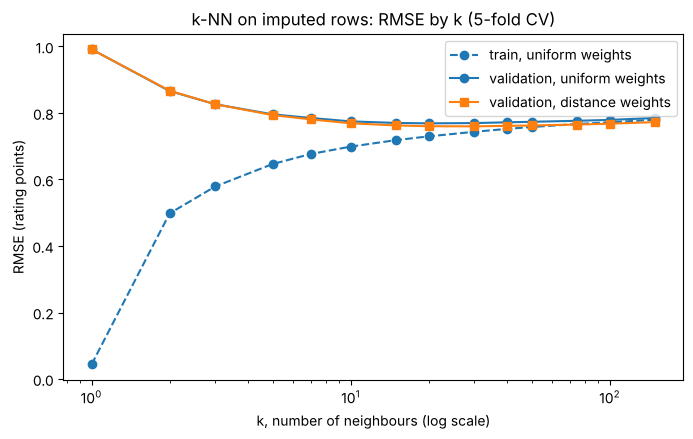

n_neighbors                 1      2      3      5      7      10     15   \
uniform  train RMSE       0.044  0.498  0.579  0.647  0.677  0.699  0.718   
         validation RMSE  0.991  0.866  0.826  0.796  0.785  0.775  0.770   
distance train RMSE       0.044  0.034  0.033  0.033  0.033  0.033  0.033   
         validation RMSE  0.991  0.867  0.826  0.794  0.781  0.769  0.762   

n_neighbors                 20     30     40     50     75     100    150  
uniform  train RMSE       0.730  0.743  0.752  0.758  0.767  0.772  0.780  
         validation RMSE  0.769  0.770  0.772  0.774  0.777  0.779  0.785  
distance train RMSE       0.033  0.033  0.033  0.033  0.033  0.033  0.033  
         validation RMSE  0.760  0.760  0.761  0.762  0.765  0.768  0.773

In [17]:
# [AI-assisted] Claude Code, 2026-11-10. k sweep for k-NN with both weightings; reviewed and edited by Ansel Weng.
ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100, 150]
k_sweep_u = sweep(knn_pipe(IMPUTER, weights="uniform"), "model__n_neighbors", ks, X_train, y_train)
k_sweep_d = sweep(knn_pipe(IMPUTER, weights="distance"), "model__n_neighbors", ks, X_train, y_train)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, k_sweep_u["train RMSE"], "o--", color="tab:blue", label="train, uniform weights")
ax.plot(ks, k_sweep_u["validation RMSE"], "o-", color="tab:blue", label="validation, uniform weights")
ax.plot(ks, k_sweep_d["validation RMSE"], "s-", color="tab:orange", label="validation, distance weights")
ax.set_xscale("log")
ax.set_title("k-NN on imputed rows: RMSE by k (5-fold CV)")
ax.set_xlabel("k, number of neighbours (log scale)")
ax.set_ylabel("RMSE (rating points)")
ax.legend()
save("05_knn_k_sweep.png")
plt.show()
pd.concat({"uniform": k_sweep_u, "distance": k_sweep_d}, axis=1).round(3).T

**Takeaway:** with equal weights, k = 1 memorizes the training games (training RMSE 0.044, validation 0.991); validation RMSE falls to 0.769 at k = 20 and drifts up after that as the neighbourhoods get too broad. Distance weighting is better at every k from 5 up, bottoming out at 0.760 for k = 20 to 30. (Its training RMSE of 0.033 is not overfitting: each training game is its own nearest neighbour at distance zero, as notebook 04 explains; the equal-weight curves are the fit diagnostic.)

### 6b. Grid search over three hyperparameters

k, the neighbour weighting, and the distance measure (`p = 1` Manhattan, `p = 2` Euclidean). Notebook 04 tuned only the first two.

In [18]:
# [AI-assisted] Claude Code, 2026-11-10. GridSearchCV for k-NN on imputed rows; reviewed and edited by Ansel Weng.
knn_grid_params = {"model__n_neighbors": [10, 15, 20, 30, 40, 50, 75], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}
knn_grid = GridSearchCV(knn_pipe(IMPUTER), knn_grid_params, cv=folds, scoring=RMSE, n_jobs=-1)
knn_grid.fit(X_train, y_train)
print("best settings:", knn_grid.best_params_, "| CV RMSE:", round(-knn_grid.best_score_, 4))
table = pd.DataFrame(knn_grid.cv_results_)
(-table.pivot_table(index="param_model__n_neighbors", columns=["param_model__p", "param_model__weights"], values="mean_test_score")).round(3)

best settings: {'model__n_neighbors': 30, 'model__p': 1, 'model__weights': 'distance'} | CV RMSE: 0.7403


param_model__p                  1                2        
param_model__weights     distance uniform distance uniform
param_model__n_neighbors                                  
10                          0.750   0.755    0.769   0.775
15                          0.742   0.749    0.762   0.770
20                          0.741   0.749    0.760   0.769
30                          0.740   0.750    0.760   0.770
40                          0.741   0.752    0.761   0.772
50                          0.742   0.753    0.762   0.774
75                          0.745   0.757    0.765   0.777

## 7. The drop approach, tuned the same way

For a fair comparison the drop approach gets the same treatment: the same grids, tuned by 5-fold cross-validation, but on the complete training games only. No imputer is needed there; a median imputer is left in the pipeline only so the same code runs, and it never fills anything because these rows have no missing inputs.

In [19]:
# [AI-assisted] Claude Code, 2026-11-10. Tune the tree and k-NN on the complete training games only; reviewed and edited by Ansel Weng.
X_train_cc, y_train_cc = X_train[train_complete], y_train[train_complete]
assert X_train_cc.isna().sum().sum() == 0
tree_grid_cc = GridSearchCV(tree_pipe("median"), tree_grid_params, cv=folds, scoring=RMSE, n_jobs=-1).fit(X_train_cc, y_train_cc)
knn_grid_cc = GridSearchCV(knn_pipe("median"), knn_grid_params, cv=folds, scoring=RMSE, n_jobs=-1).fit(X_train_cc, y_train_cc)
print("training games:", len(X_train_cc))
print("tree best:", tree_grid_cc.best_params_, "| CV RMSE:", round(-tree_grid_cc.best_score_, 4))
print("k-NN best:", knn_grid_cc.best_params_, "| CV RMSE:", round(-knn_grid_cc.best_score_, 4))

training games: 12611
tree best: {'model__max_depth': 10, 'model__min_samples_leaf': 75} | CV RMSE: 0.6895
k-NN best: {'model__n_neighbors': 20, 'model__p': 1, 'model__weights': 'distance'} | CV RMSE: 0.7202


## 8. Score the test rows once

Every model below is fitted on its own training rows and scored once. Three sets of test games:

- **complete test games**: the games both approaches can predict. This is the like-for-like comparison of drop versus impute.
- **all test games**: what the impute approach delivers in practice. The drop approach cannot score the games with a missing input at all.
- **test games with a missing input**: how well the imputed model does on exactly the games the drop approach throws away.

In [20]:
# [AI-assisted] Claude Code, 2026-11-10. Fit baselines and the four tuned models, and score them on the three sets of test games; reviewed and edited by Ansel Weng.
X_test_cc, y_test_cc = X_test[test_complete], y_test[test_complete]
X_test_mi, y_test_mi = X_test[~test_complete], y_test[~test_complete]

models = {
    "drop":   {"Baseline (DummyRegressor)": DummyRegressor().fit(X_train_cc, y_train_cc),
               "Regression tree": tree_grid_cc.best_estimator_, "k-NN": knn_grid_cc.best_estimator_},
    "impute": {"Baseline (DummyRegressor)": DummyRegressor().fit(X_train, y_train),
               "Regression tree": tree_grid.best_estimator_, "k-NN": knn_grid.best_estimator_},
}
cv_scores = {("drop", "Regression tree"): -tree_grid_cc.best_score_, ("drop", "k-NN"): -knn_grid_cc.best_score_,
             ("impute", "Regression tree"): -tree_grid.best_score_, ("impute", "k-NN"): -knn_grid.best_score_}

test_sets = {"complete test games": (X_test_cc, y_test_cc), "all test games": (X_test, y_test), "test games with a missing input": (X_test_mi, y_test_mi)}
rows = []
for set_name, (X, y) in test_sets.items():
    for approach, group in models.items():
        if approach == "drop" and set_name != "complete test games":
            continue  # the drop approach cannot score games with a missing input
        for name, m in group.items():
            rows.append({"approach": approach, "model": name, "test games": set_name, "n": len(y),
                         "CV RMSE (train)": cv_scores.get((approach, name), np.nan), **test_scores(y, m.predict(X))})
final = pd.DataFrame(rows).set_index(["test games", "approach", "model"])
final.round(3)

n  \
test games                      approach model                             
complete test games             drop     Baseline (DummyRegressor)  5371   
                                         Regression tree            5371   
                                         k-NN                       5371   
                                impute   Baseline (DummyRegressor)  5371   
                                         Regression tree            5371   
                                         k-NN                       5371   
all test games                  impute   Baseline (DummyRegressor)  6490   
                                         Regression tree            6490   
                                         k-NN                       6490   
test games with a missing input impute   Baseline (DummyRegressor)  1119   
                                         Regression tree            1119   
                                         k-NN                       1119   

                                                                    CV RMSE (train)  \
test games                      approach model                                        
complete test games             drop     Baseline (DummyRegressor)              NaN   
                                         Regression tree                       0.69   
                                         k-NN                                  0.72   
                                impute   Baseline (DummyRegressor)              NaN   
                                         Regression tree                       0.71   
                                         k-NN                                  0.74   
all test games                  impute   Baseline (DummyRegressor)              NaN   
                                         Regression tree                       0.71   
                                         k-NN                                  0.74   
test games with a missing input impute   Baseline (DummyRegressor)              NaN   
                                         Regression tree                       0.71   
                                         k-NN                                  0.74   

                                                                    test RMSE  \
test games                      approach model                                  
complete test games             drop     Baseline (DummyRegressor)      0.885   
                                         Regression tree                0.673   
                                         k-NN                           0.710   
                                impute   Baseline (DummyRegressor)      0.886   
                                         Regression tree                0.678   
                                         k-NN                           0.711   
all test games                  impute   Baseline (DummyRegressor)      0.922   
                                         Regression tree                0.705   
                                         k-NN                           0.728   
test games with a missing input impute   Baseline (DummyRegressor)      1.076   
                                         Regression tree                0.824   
                                         k-NN                           0.803   

                                                                    test MAE  \
test games                      approach model                                 
complete test games             drop     Baseline (DummyRegressor)     0.697   
                                         Regression tree               0.514   
                                         k-NN                          0.545   
                                impute   Baseline (DummyRegressor)     0.700   
                                         Regression tree               0.517   
                                         k-NN                          0.546   
all test gam

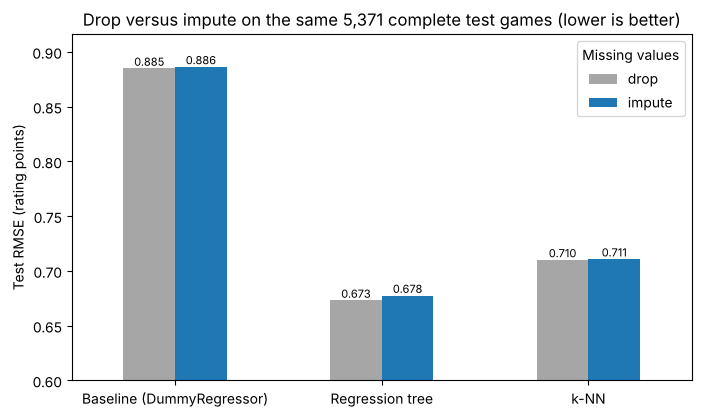

In [21]:
# [AI-assisted] Claude Code, 2026-11-10. Chart of test RMSE on the complete test games, drop versus impute; reviewed and edited by Ansel Weng.
like = final.xs("complete test games")["test RMSE"].unstack("approach")[["drop", "impute"]]
ax = like.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["0.65", "tab:blue"])
ax.set_ylim(0.6, like.values.max() + 0.03)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_title(f"Drop versus impute on the same {len(y_test_cc):,} complete test games (lower is better)")
ax.set_xlabel("")
ax.set_ylabel("Test RMSE (rating points)")
ax.legend(title="Missing values")
save("05_drop_vs_impute.png")
plt.show()

**Takeaway: on the same 5,371 complete test games, imputing and dropping are a tie.** The tuned tree scores 0.673 when trained on complete games only and 0.678 when trained on every game with imputation; k-NN 0.710 against 0.711. Adding 2,530 harder, imputed training games costs at most 0.005 RMSE on the complete games.

**What imputing buys is the other 1,119 test games (17%)**, which the drop approach cannot score at all. On those, the imputed tree has RMSE 0.824 against 1.076 for the baseline (R² 0.38), and k-NN 0.803 (R² 0.41). They are harder games to predict (the baseline is 0.19 worse on them than on complete games) but the models still recover about as much of their variance as on complete games. Across **all** 6,490 test games the imputed tree scores RMSE 0.705, MAE 0.535, R² 0.415, against 0.922 for the baseline.

The cross-validated RMSEs differ for the same reason: the impute approach is cross-validated on all training games, including the harder incomplete ones (tree 0.710, k-NN 0.740), the drop approach on complete games only (0.690 and 0.720). Those numbers are not comparable with each other; the complete-test-games rows are.

## 9. What the tuned tree uses on the imputed rows

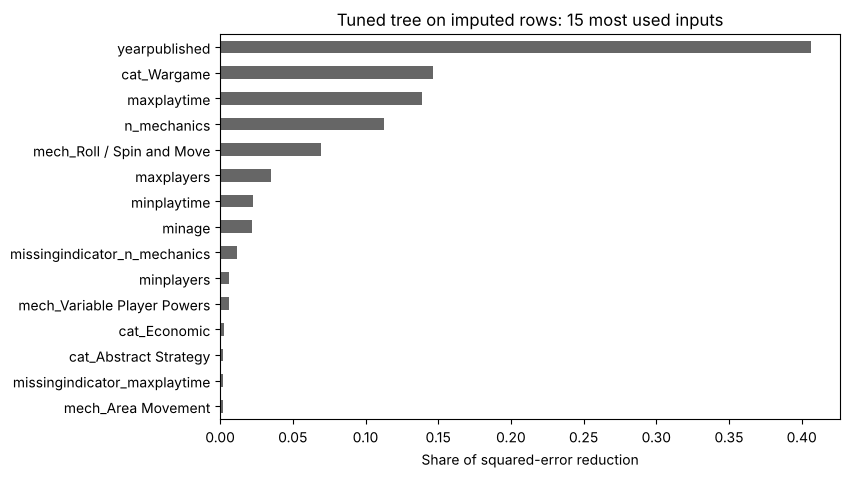

yearpublished                   0.406
cat_Wargame                     0.147
maxplaytime                     0.139
n_mechanics                     0.113
mech_Roll / Spin and Move       0.070
maxplayers                      0.035
minplaytime                     0.023
minage                          0.022
missingindicator_n_mechanics    0.012
minplayers                      0.006
mech_Variable Player Powers     0.006
cat_Economic                    0.003
cat_Abstract Strategy           0.002
missingindicator_maxplaytime    0.002
mech_Area Movement              0.002
dtype: float64

In [22]:
# [AI-assisted] Claude Code, 2026-11-10. Feature importance of the tuned tree on imputed rows; reviewed and edited by Ansel Weng.
tree_final = tree_grid.best_estimator_
names = tree_final.named_steps["impute"].get_feature_names_out(X_train.columns)
importance = pd.Series(tree_final.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
ax = importance.head(15).plot(kind="barh", color="0.4", figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Tuned tree on imputed rows: 15 most used inputs")
ax.set_xlabel("Share of squared-error reduction")
save("05_tree_feature_importance.png")
plt.show()
importance.head(15).round(3)

**Takeaway:** year of publication is still the dominant input (0.41 of the squared-error reduction, 0.43 in notebook 04), followed by the wargame category (0.15), maximum play time (0.14) and the number of mechanics (0.11). The "n_mechanics was missing" flag appears in ninth place (0.012): the tree does use the fact that a game has no mechanic list as information, which is what the indicator columns were added for.

## 10. The decision for the group chat

**Missing values: impute, do not drop.** Keep all 21,631 games, split 70/30 with `random_state=1`, and fill missing inputs with `SimpleImputer(strategy="median", add_indicator=True)` as the first step of every model's `Pipeline`, so it is fitted on training rows only.

Why: (1) the games with a missing input rate lower and have fewer raters, so dropping them biases the rows; (2) on the games both approaches can score, imputing is within 0.005 RMSE of dropping, so nothing is lost; (3) imputing lets the model score 17% more games, with a clear gain over the baseline on them; (4) median + indicator is best or within 0.002 of the best of five imputers for every model, and is the fastest.

Tuned settings on the imputed rows: **tree** `max_depth=10, min_samples_leaf=30` (CV RMSE 0.710); **k-NN** `n_neighbors=30, weights="distance", p=1` (CV RMSE 0.740). Test, all 6,490 games: tree RMSE 0.705, MAE 0.535, R² 0.415; k-NN 0.728, 0.558, 0.377; baseline 0.922.

Code to paste into the other predictive notebooks (tasks 2, 3, 4 and 10), replacing notebook 04's `dropna` cell:

```python
# Rows and missing values, as settled by task 1 (notebook 05_imputation_tuning_ansel).
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
data = games.copy()                                   # keep every game; do not dropna
train_df, test_df = train_test_split(data, test_size=0.3, random_state=1)
# build X_train / X_test with notebook 04's build_inputs (top mechanics and categories from train_df only),
# then put the imputer as the first step of every model's Pipeline:
#   tree = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
#                    ("model", DecisionTreeRegressor(max_depth=10, min_samples_leaf=30, random_state=0))])
#   knn  = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
#                    ("model", KNeighborsRegressor(n_neighbors=30, weights="distance", p=1))])
```

## 11. What did not work, and notes

- **More elaborate imputers did not pay off.** The k-NN imputer and the iterative imputer took about 25 and 90 times as long as median + indicator and improved the tree and k-NN by at most 0.002 RMSE, while doing worse for linear regression. Kept in section 4 as evidence.
- **Plain mean or median imputation without the indicator** was 0.011 worse for linear regression: filling a gap with a typical value hides the fact that it was missing, and missingness itself predicts a lower rating.
- **Imputing did not improve the score on complete games.** It was slightly worse (tree 0.678 against 0.673). The gain from imputing is coverage, not accuracy on the games we already had.
- **An unconstrained deep tree overfits badly** (validation RMSE 0.895 at depth 20 with one game per leaf); the leaf-size limit is what makes depth safe.
- **Euclidean distance (p = 2) was worse for k-NN** than Manhattan distance (p = 1) at every k, by about 0.02 CV RMSE. Notebook 04 only used Euclidean; the third hyperparameter added here is worth keeping.

- One split (70/30, `random_state=1`) of all 21,631 games is used throughout; the complete-case rows on each side are a subset of that same split.
- Every number labelled "CV" comes from 5-fold cross-validation on training rows only; every number labelled "test" comes from scoring once, at the end.
- Figures are saved to `figures/` with the prefix `05_`.